Stage 5.1: Dataset Exploration
This stage intends to investigate the dataset provided for Perovskite solar cells; gaining a familiarity with the variables used, combining the reading physics with practical results and linking this to the Hussain paper we are basing our research project on.
The original dataset will not yet be modified.

In [51]:
import pandas as pd

df = pd.read_csv('/Users/josh_hesse/Documents/University/Year 3/Perovskite-Research/PerovskiteMLproject_2627/Data/Perovskite_database_full.csv', 
                encoding="cp1252", #Encodes with windows-1252 encoding to handle special characters.
                low_memory=False #Makes code more robust to data type inference issues.
                )

print(df.shape)

(42851, 410)


This has imported the dataset and verifies it has the correct number of columns/rows: 42851/410 respectively. Now we want to know what each column is describing.

We can see that many columns don't have sufficient data or aren't the area we are investigating. For this preliminary task of recreating the Hussain paper's results, we will narrow this immediately to 20 helpful data-points.


| Category | Column Names | Purpose |
|---|---|---|
| **Reference** | `Ref_ID`, `Ref_DOI_number` | Identify and trace experimental records to their original publications. |
| **Composition** | `Perovskite_composition_a_ions`, `Perovskite_composition_a_ions_coefficients`, `Perovskite_composition_b_ions`, `Perovskite_composition_b_ions_coefficients`, `Perovskite_composition_c_ions`, `Perovskite_composition_c_ions_coefficients` | Describe the chemical composition and stoichiometric ratios of the perovskite absorber. |
| **Material Properties** | `Perovskite_composition_short_form`, `Perovskite_band_gap` | Identify the material and its electronic band gap. |
| **Device Structure** | `Cell_architecture`, `Cell_area_measured`, `Substrate_stack_sequence`, `ETL_stack_sequence`, `HTL_stack_sequence`, `Backcontact_stack_sequence` | Describe the solar-cell architecture, transport layers, electrodes and measured area. |
| **Performance** | `JV_default_PCE`, `JV_default_Jsc`, `JV_default_Voc`, `JV_default_FF` | Quantify device efficiency, current density, voltage and fill factor. |

These columns also provide a foundation for initial machine-learning models predicting material properties and device performance.

Other variables relating to fabrication, stability and outdoor performance are excluded from this analysis but remain in the original dataset.


In [52]:
df_hussain = df[[
    # Reference
    'Ref_ID',
    'Ref_DOI_number',

    # Composition
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',

    # Material Properties
    'Perovskite_composition_short_form',
    'Perovskite_band_gap',

    # Device Structure
    'Cell_architecture',
    'Cell_area_measured',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence',

    # Performance
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]].copy() #Pandas requires double square brackets to select multiple columns.

print(df_hussain.shape)

(42851, 20)


With the rows narrowed down, we can filter the remaining data into seperate datasets, targetting each of the 3 figures we want to recreate:
1) Figure 1(a): A simple count of what materials have been studied and how many times.
2) Figure 3(a): The main goal of this preliminary step, comparing the PCE against the Band gap (E_g) of the cleaned dataset.
3) Figure 3(f): Comparing the current density against band gap to demonstrate how a wider range of wavelengths does not result in a "better" solar cell.

In [53]:
from pathlib import Path
#AI, prompt: The essential field to recreate the Hussain results is "Perovskite_composition_short_form", as in it is unusable if it doesn't contain this, identify all that don't have usable data in this field.
missing_composition = df_hussain[
    'Perovskite_composition_short_form'
].isna().sum()

print("Missing composition:", missing_composition)






# Create a folder for the figure-specific datasets
output_folder = Path("Data/Hussain_Replication")

# Figure 1(a): Material distribution
df_fig1 = df_hussain.dropna(
    subset=['Perovskite_composition_short_form']
).copy()

# Figure 3(a): Band gap versus PCE
df_fig3a = df_hussain.dropna(
    subset=['Perovskite_band_gap', 'JV_default_PCE']
).copy()

# Figure 3(f): Band gap versus Jsc
df_fig3f = df_hussain.dropna(
    subset=['Perovskite_band_gap', 'JV_default_Jsc']
).copy()

# Save each dataset separately
df_fig1.to_csv(
    output_folder / "Fig1_Material_Distribution.csv",
    index=False
)

df_fig3a.to_csv(
    output_folder / "Fig3a_Bandgap_vs_PCE.csv",
    index=False
)

df_fig3f.to_csv(
    output_folder / "Fig3f_Bandgap_vs_Jsc.csv",
    index=False
)

# Check how many experimental records remain
print("Original dataset:", len(df_hussain))
print("Figure 1(a):", len(df_fig1))
print("Figure 3(a):", len(df_fig3a))
print("Figure 3(f):", len(df_fig3f))


Missing composition: 32
Original dataset: 42851
Figure 1(a): 42819
Figure 3(a): 31681
Figure 3(f): 30797


With initial filtering complete we can focus on each figure individually. Beginning with Figure 1(a), as it is the most straight forward. Then we will begin cleaning down to the ~700 entries used in the Hussain paper for regression analysis.
To do this we must compile all of the same material combinations together, this presents a challenge as perovskites can have different names but identical structure (e.g: MAPbI3 and CH3NH3PbI3 are identical but presented differently in some reports).

In [54]:
composition_counts = (
    df_fig1['Perovskite_composition_short_form']
    .value_counts()
)

print("Unique compositions:", len(composition_counts))
print(composition_counts.head(20))

Unique compositions: 462
Perovskite_composition_short_form
MAPbI          26869
CsFAMAPbBrI     3801
FAMAPbBrI       2888
FAMAPbI          926
CsPbBrI          912
CsFAPbBrI        698
MAPbBrI          622
FAPbI            577
CsPbBr           445
CsPbI            437
CsFAPbI          390
MAPbBr           297
BAMAPbI          207
FASnI            204
MAPbSnI          154
(PEA)MAPbI       125
FAMAPbSnI        124
CsFAMAPbI        107
FAPbBrI           97
MABiI             93
Name: count, dtype: int64


The results aren't noticably spread between duplicate-alternate-formats. This provides reliable, unique material combinations to plot figure 1(a) initially.
It also presents an issue for the upcoming machine learning section: By being so heavily skewed towards MAPbI, the trained model will be biased towards combinations included in this structure over others; while we will have to see the effects directly, we can prepare for this when building the model.

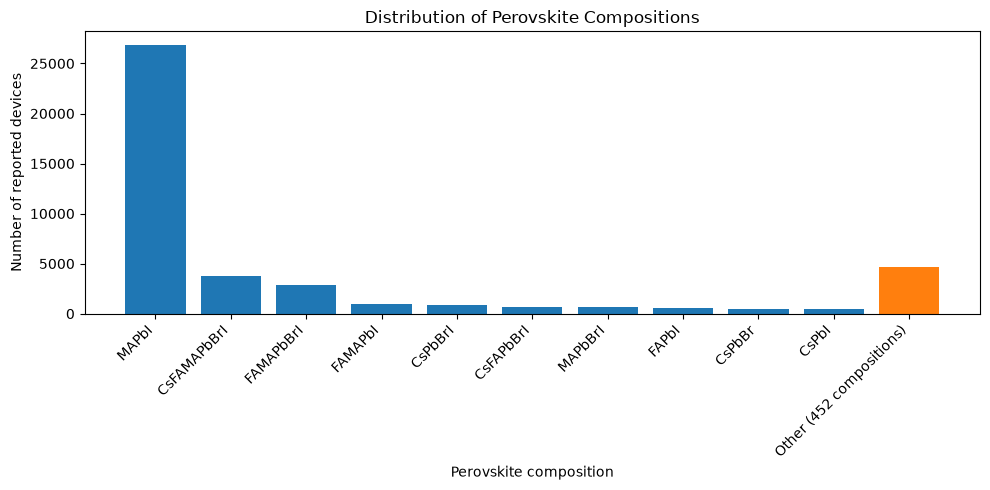

In [55]:
import matplotlib.pyplot as plt

top_10 = composition_counts.head(10)

plt.figure(figsize=(10, 5))
plt.bar(top_10.index, top_10.values)
other_count = composition_counts.iloc[10:].sum()
plt.bar("Other (" + str(len(composition_counts) - 10) + " compositions)", other_count)

plt.xlabel("Perovskite composition")
plt.ylabel("Number of reported devices")
plt.title("Distribution of Perovskite Compositions")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## Preparing data for ML
We now move to the actual recreation of regression models used in the Hussain paper. This is done by 5 filters to reduce ~42,000 entries to ~700, similiarly to the Hussain model. The filters used are taken directly from the description in the "Data Preparation" section of the paper, and applied ourselves on our own data.
The filters are, in order of application:
1) Required measurements - Ensuring required data is present, or the row is purged.
2) Permitted peroskite ions - Filters to only include: MA, FA, Cs / Pb, Sn / I, Br, Cl ions in A / B / X positions respectively.
3) Common device configuration - One of the most influential choices was choosing common HTL/ETL and substrate setups. This is done by only using setups that have >100 records and then using the 5 most common of these for a given ion combination, to reduce impact of device setup on the readings.
4) Exact duplicates - If combination, setup and readings are identical, these points are aggregated into a single point as to not bias training.
5) Physical identifiers - Identifiers unphysical results (Positive, finite energy reading; PCE between 0%-100%; current density is positive) and removes these if they fall far beyond possible results. This is the most uncertain filter, so it is left until last to be reviewed manually.


In [56]:

# FILTER SETTINGS
# Required measurements
REQUIRE_ALL_PARAMETERS = True

# Permitted chemical species
ALLOWED_A = ['MA', 'FA', 'Cs']
ALLOWED_B = ['Pb', 'Sn']
ALLOWED_X = ['I', 'Br', 'Cl']

# Device-layer filtering
LAYER_FILTER_METHOD = 'min_frequency'
MIN_LAYER_FREQUENCY = 100
TOP_N_LAYERS = 5

# Duplicate handling
DUPLICATE_METHOD = 'exact'

# Outlier handling
REMOVE_INVALID_VALUES = True
REMOVE_STATISTICAL_OUTLIERS = False



#Filter 1: Filter based on required measurements:
df_filtered_temp = df_hussain.dropna(
    subset=[
    'Perovskite_composition_short_form',
    'Perovskite_band_gap',
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

).copy()
print("Before filter 1:", len(df_hussain)) #42851
print("After filter 1:", len(df_filtered)) #30529
print("Removed by filter 1:", len(df_hussain) - len(df_filtered)) #12322


Before filter 1: 42851
After filter 1: 30529
Removed by filter 1: 12322


In [57]:
#Filter 2: Filter based on allowed chemical species:
#Testing shows multuple ions in a single cell are separated by a semicolon.
ALLOWED_A = ['MA', 'FA', 'Cs']
ALLOWED_B = ['Pb', 'Sn']
ALLOWED_X = ['I', 'Br', 'Cl']

def valid_ions(cell, allowed):
    if pd.isna(cell): #Checks if the field is present and not NaN.
        return False

    ions = [ion.strip() for ion in str(cell).split(';')] #Seperates compounds of ions into individual ions.

    return all(ion in allowed for ion in ions) #Ensures every ion present in the cell is in the allowed list. Even if some are allowed, returns False.



valid_a = df_filtered['Perovskite_composition_a_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_A)
)

valid_b = df_filtered['Perovskite_composition_b_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_B)
)

valid_x = df_filtered['Perovskite_composition_c_ions'].apply(
    lambda value: valid_ions(value, ALLOWED_X)
)

df_filtered_2 = df_filtered[
    valid_a & valid_b & valid_x
].copy() #Creates a new dataframe with only the valid rows based on the allowed ions, seperating impact of filter 2 from filter 1.

print("Before Filter 2:", len(df_filtered))
print("After Filter 2:", len(df_filtered_2))
print("Removed by filter 2:", len(df_filtered) - len(df_filtered_2))

Before Filter 2: 30529
After Filter 2: 29467
Removed by filter 2: 1062


In [58]:
#Filter 3 - Preliminary
layer_columns = [
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

for column in layer_columns:
    print("\n", column)
    print(df_filtered_2[column].value_counts().head(10))


 Substrate_stack_sequence
Substrate_stack_sequence
SLG | FTO    17596
SLG | ITO    10642
PET | ITO      257
PEN | ITO      168
PET | IZO       62
SLG             31
PET             27
SLG | AZO       25
Ti              22
Ti-foil         17
Name: count, dtype: int64

 ETL_stack_sequence
ETL_stack_sequence
TiO2-c | TiO2-mp              7581
TiO2-c                        4705
PCBM-60                       2598
PCBM-60 | BCP                 1874
C60 | BCP                     1141
SnO2-np                        834
SnO2-c                         728
TiO2-c | TiO2-mp | ZrO2-mp     534
ZnO-c                          362
PCBM-60 | LiF                  328
Name: count, dtype: int64

 HTL_stack_sequence
HTL_stack_sequence
Spiro-MeOTAD    14144
PEDOT:PSS        4970
none             1938
NiO-c            1233
PTAA             1209
P3HT              618
NiO-np            289
CuSCN             129
NiMgLiO           119
P3CT-Na           118
Name: count, dtype: int64

 Backcontact_stack_sequence
B

This demonstrates the most common 10 layouts for each of the stack type (ETL, HTL, Back-contact, Substrate). To copy the Hussain results we take any readings that have >100 experiments using the stack layout, and if there are >5 of these for a given stack, we take the most common 5. 

In [59]:
#Filter 3: : Filter based on device-layer frequency:
MIN_FREQUENCY = 100
TOP_N = 5

layer_columns = [
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

# Function to identify accepted layer sequences
def accepted_layers(data, column, min_frequency, top_n):

    # Count occurrences of each layer sequence
    counts = data[column].value_counts()

    # Keep sequences meeting minimum frequency
    counts = counts[counts >= min_frequency]

    # Select the most common N sequences
    return counts.head(top_n).index


# Start with our Filter 2 dataset
df_filtered_3 = df_filtered_2.copy()

# Apply restrictions for each device layer
for column in layer_columns:

    allowed = accepted_layers(
        df_filtered_2,
        column,
        MIN_FREQUENCY,
        TOP_N
    )

    # Retain rows with an accepted layer sequence
    df_filtered_3 = df_filtered_3[
        df_filtered_3[column].isin(allowed)
    ].copy()

    print(column, "- accepted sequences:", list(allowed))


# Display final results
print("\nBefore Filter 3:", len(df_filtered_2))
print("After Filter 3:", len(df_filtered_3))
print("Removed by Filter 3:",
      len(df_filtered_2) - len(df_filtered_3))


Substrate_stack_sequence - accepted sequences: ['SLG | FTO', 'SLG | ITO', 'PET | ITO', 'PEN | ITO']
ETL_stack_sequence - accepted sequences: ['TiO2-c | TiO2-mp', 'TiO2-c', 'PCBM-60', 'PCBM-60 | BCP', 'C60 | BCP']
HTL_stack_sequence - accepted sequences: ['Spiro-MeOTAD', 'PEDOT:PSS', 'none', 'NiO-c', 'PTAA']
Backcontact_stack_sequence - accepted sequences: ['Au', 'Ag', 'Al', 'Carbon', 'MoO3 | Ag']

Before Filter 3: 29467
After Filter 3: 12709
Removed by Filter 3: 16758


In [60]:
# FILTER 4: INVESTIGATE DUPLICATES

duplicate_columns = [
    'Ref_DOI_number',
    'Perovskite_composition_short_form',
    'Perovskite_band_gap',
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence',
    'JV_default_PCE',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

duplicates = df_filtered_3.duplicated(
    subset=duplicate_columns,
    keep='first'
)

print("Before Filter 4:", len(df_filtered_3))
print("Potential duplicates:", duplicates.sum())
print("Remaining if removed:", len(df_filtered_3) - duplicates.sum())

Before Filter 4: 12709
Potential duplicates: 269
Remaining if removed: 12440


In [61]:
#Filter 5: Physical validity checks

# Adjustable validity ranges
# None means no upper/lower bound is applied.

VALID_RANGES = {
    'Perovskite_band_gap': (0, None),
    'JV_default_PCE': (0, 100),
    'JV_default_Jsc': (0, None),
    'JV_default_Voc': (0, None),
}

# Start from Filter 3.
# We have NOT approved duplicate removal yet.
df_filtered_5 = df_filtered_3.copy()

print("Before Filter 5:", len(df_filtered_5))

for column, (minimum, maximum) in VALID_RANGES.items():

    # Convert values to numeric form
    values = pd.to_numeric(
        df_filtered_5[column],
        errors='coerce'
    )

    # Require a valid, finite number
    valid = values.notna()
    valid = valid & (values != float('inf'))
    valid = valid & (values != float('-inf'))

    # Apply chosen limits
    if minimum is not None:
        valid = valid & (values >= minimum)

    if maximum is not None:
        valid = valid & (values <= maximum)

    # Remove invalid observations
    before = len(df_filtered_5)
    df_filtered_5 = df_filtered_5[valid].copy()

print(column, "- removed:", before - len(df_filtered_5))
print("\nAfter Filter 5:", len(df_filtered_5))
print("Removed by Filter 5:",
      len(df_filtered_3) - len(df_filtered_5))


Before Filter 5: 12709
JV_default_Voc - removed: 0

After Filter 5: 12709
Removed by Filter 5: 0


We later realised that a single entry that passed all other checks contained an "X" in the "Perovskite_composition_c_ions_coefficient" field. This should only contain numbers and ";" to seperate multi-ion compositions. So an additional check to all three coefficients is added.

In [62]:
coefficient_columns = [
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions_coefficients'
]

# Check that every coefficient is numeric
def valid_coefficients(value):

    if pd.isna(value):
        return False

    # Split multiple coefficients, e.g. "0.8; 0.2"
    coefficients = str(value).split(';')

    for coefficient in coefficients:
        coefficient = coefficient.strip()

        if coefficient == '':
            return False

        try:
            number = float(coefficient)
            if not pd.notna(number):
                return False

            # Coefficients must be positive
            if number <= 0:
                return False

        except ValueError:
            return False

    return True


# Apply the validation to all three columns
before = len(df_filtered_5)

valid_rows = pd.Series(
    True,
    index=df_filtered_5.index
)

for column in coefficient_columns:

    valid_rows &= df_filtered_5[column].apply(
        valid_coefficients
    )

# Show invalid entries before removing them
invalid_records = df_filtered_5.loc[
    ~valid_rows,
    coefficient_columns
]

print("Invalid coefficient records:", len(invalid_records))

display(invalid_records.head(10))

# Remove records with invalid coefficients
df_filtered_5 = df_filtered_5.loc[valid_rows].copy()

print("Records before:", before)
print("Records after:", len(df_filtered_5))
print("Records removed:", before - len(df_filtered_5))

Invalid coefficient records: 6


,Perovskite_composition_a_ions_coefficients,Perovskite_composition_b_ions_coefficients,Perovskite_composition_c_ions_coefficients
21799,1,NaN,1.26; 1.74
21800,1,NaN,1.77; 1.23
21801,1,NaN,2.16; 0.84
21802,1,NaN,2.85; 0.15
39475,1,1,x
42669,NaN,0.5; 0.5,3


Records before: 12709
Records after: 12703
Records removed: 6


These results do not align with the expected Hussain results of ~700 compared to ~13,000. So we need to identify if the issues are raised by: the code used, the constraint values used or incorrect interpretation of Hussain's method. 

Checks were completed on the code and all results aligned with expected results. Reconsulting the Hussain paper showed that the issue was definition of "results" we've been working with. The targeted ~700 "results" each represent an experiment configuration; meanwhile we have been treating each result as an individual test, which explains the difference in results.
When filtering for configurations, this brings out ~13,000 results to ~687.

In [63]:
# Group observations by their device configuration
configuration_summary = (
    df_filtered_3
    .groupby(configuration_columns, dropna=False)
    .agg(
        n_records=('JV_default_PCE', 'size'),
        mean_PCE=('JV_default_PCE', 'mean'),
        std_PCE=('JV_default_PCE', 'std'),
        min_PCE=('JV_default_PCE', 'min'),
        max_PCE=('JV_default_PCE', 'max')
    )
    .reset_index()
)

# Show the 10 most frequently repeated configurations
display(
    configuration_summary
    .sort_values('n_records', ascending=False)
    .head(10)
)

,Perovskite_composition_a_ions,Perovskite_composition_a_ions_coefficients,Perovskite_composition_b_ions,Perovskite_composition_b_ions_coefficients,Perovskite_composition_c_ions,Perovskite_composition_c_ions_coefficients,Cell_architecture,Substrate_stack_sequence,ETL_stack_sequence,HTL_stack_sequence,Backcontact_stack_sequence,n_records,mean_PCE,std_PCE,min_PCE,max_PCE
542,MA,1,Pb,1,I,3,nip,SLG | FTO,TiO2-c | TiO2-mp,Spiro-MeOTAD,Au,3152,11.879804,4.395323,0.0000,20.90
531,MA,1,Pb,1,I,3,nip,SLG | FTO,TiO2-c,Spiro-MeOTAD,Au,1651,12.513688,4.574130,0.0000,22.08
529,MA,1,Pb,1,I,3,nip,SLG | FTO,TiO2-c,Spiro-MeOTAD,Ag,841,12.066302,4.182134,0.0300,20.20
540,MA,1,Pb,1,I,3,nip,SLG | FTO,TiO2-c | TiO2-mp,Spiro-MeOTAD,Ag,834,12.255168,4.112103,0.5300,21.33
616,MA,1,Pb,1,I,3,pin,SLG | ITO,PCBM-60,PEDOT:PSS,Al,554,9.902287,4.133517,0.0007,18.90
626,MA,1,Pb,1,I,3,pin,SLG | ITO,PCBM-60 | BCP,PEDOT:PSS,Ag,429,11.752844,3.811094,0.0300,19.20
615,MA,1,Pb,1,I,3,pin,SLG | ITO,PCBM-60,PEDOT:PSS,Ag,408,10.073235,3.660066,0.0900,19.20
547,MA,1,Pb,1,I,3,nip,SLG | FTO,TiO2-c | TiO2-mp,none,Carbon,345,8.141594,3.393968,0.0000,18.79
563,MA,1,Pb,1,I,3,nip,SLG | ITO,TiO2-c,Spiro-MeOTAD,Au,232,13.255043,4.618840,0.0100,20.27
624,MA,1,Pb,1,I,3,pin,SLG | ITO,PCBM-60 | BCP,NiO-c,Ag,176,13.880852,3.998251,0.1000,20.18


This provides the 10 most common configurations, with a range of 3,152 - 176 in the top 10 results. Which explains the difference in results. Now we want to check how many of these configurations only have a single experiment, and we can consider removing these.

In [64]:
print("Total configurations:", len(configuration_summary))

print(
    "Configurations with 1 record:",
    (configuration_summary['n_records'] == 1).sum()
)

print(
    "Configurations with 2–5 records:",
    configuration_summary['n_records'].between(2, 5).sum()
)

print(
    "Configurations with more than 5 records:",
    (configuration_summary['n_records'] > 5).sum()
)

Total configurations: 687
Configurations with 1 record: 350
Configurations with 2–5 records: 210
Configurations with more than 5 records: 127


In [68]:
#Aggregation by configuration

from pathlib import Path

MIN_RECORDS = 1  # Minimum observations per configuration

OUTPUT_FOLDER = Path("Data/Hussain_Replication")
OUTPUT_FILE = OUTPUT_FOLDER / "Aggregated_Configurations.csv"



configuration_columns = [
    # Perovskite composition
    'Perovskite_composition_a_ions',
    'Perovskite_composition_a_ions_coefficients',
    'Perovskite_composition_b_ions',
    'Perovskite_composition_b_ions_coefficients',
    'Perovskite_composition_c_ions',
    'Perovskite_composition_c_ions_coefficients',

    # Device architecture
    'Cell_architecture',
    'Substrate_stack_sequence',
    'ETL_stack_sequence',
    'HTL_stack_sequence',
    'Backcontact_stack_sequence'
]

# Convert measurement columns to numeric values
measurement_columns = [
    'JV_default_PCE',
    'Perovskite_band_gap',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

df_numeric = df_filtered_5.copy()

for column in measurement_columns:
    df_numeric[column] = pd.to_numeric(
        df_numeric[column],
        errors='coerce'
    )

df_configurations = (
    df_numeric
    .groupby(configuration_columns, dropna=False)
    .agg(
        # Number of experimental observations
        n_records=('JV_default_PCE', 'size'),

        # Power conversion efficiency
        mean_PCE=('JV_default_PCE', 'mean'),
        median_PCE=('JV_default_PCE', 'median'),
        std_PCE=('JV_default_PCE', 'std'),

        # Band gap
        mean_band_gap=('Perovskite_band_gap', 'mean'),
        median_band_gap=('Perovskite_band_gap', 'median'),
        std_band_gap=('Perovskite_band_gap', 'std'),

        # Photovoltaic parameters
        mean_Jsc=('JV_default_Jsc', 'mean'),
        std_Jsc=('JV_default_Jsc', 'std'),

        mean_Voc=('JV_default_Voc', 'mean'),
        std_Voc=('JV_default_Voc', 'std'),

        mean_FF=('JV_default_FF', 'mean'),
        std_FF=('JV_default_FF', 'std')
    )
    .reset_index()
)


df_configurations_filtered = df_configurations[
    df_configurations['n_records'] >= MIN_RECORDS
].copy()


print("Before Filter 6:", len(df_filtered_5))
print("Unique configurations:", len(df_configurations))
print("After MIN_RECORDS filter:", len(df_configurations_filtered))

print(
    "Records represented:",
    df_configurations['n_records'].sum()
)

print(
    "Single-observation configurations:",
    (df_configurations['n_records'] == 1).sum()
)

df_configurations_filtered.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding='utf-8'
)

print("\nDataset saved to:", OUTPUT_FILE)



Before Filter 6: 12703
Unique configurations: 681
After MIN_RECORDS filter: 681
Records represented: 12703
Single-observation configurations: 344

Dataset saved to: Data/Hussain_Replication/Aggregated_Configurations.csv


In [ ]:
from pathlib import Path

measurement_columns = [
    'JV_default_PCE',
    'Perovskite_band_gap',
    'JV_default_Jsc',
    'JV_default_Voc',
    'JV_default_FF'
]

print(df_filtered_5[measurement_columns].dtypes)

output_folder = Path("Data/Hussain_Replication")
output_folder.mkdir(parents=True, exist_ok=True)

df_filtered_5.to_csv(
    output_folder / "Filtered_Experimental_Records.csv",
    index=False,
    encoding="utf-8"
)

JV_default_PCE         float64
Perovskite_band_gap        str
JV_default_Jsc         float64
JV_default_Voc         float64
JV_default_FF          float64
dtype: object
